# Geometry + Colorimetry Fusion: Pre / Per / Post-Exercise Classification

This notebook combines the two approaches previously tested:
- **Colorimetry** (`colorimetry` notebook): 7 best features (selected based on Random Forest feature importance).
- **Facial Geometry** (`geometric-features` notebook): 3 best features (mouth-related features).



## 1 - Library

In [36]:
import urllib.request
from pathlib import Path

import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report, ConfusionMatrixDisplay)

# ---------- Parameters ----------
DOSSIER = Path("../dataset_computervision_LECSIN/dataset_squat")   # Adapt if needed
GROUPES = ["pre", "per", "post"]
SEED = 42
ROI_RATIO = 0.6            # Central face region used for colorimetry
Path("figures").mkdir(exist_ok=True)

# ---------- Selected features (top features from both notebooks) ----------
TOP_COLOR = ["scene_pixels_valides_pct", "gw_face_corr_bg", "moyenne_srgb_R",
               "contraste_rms", "ratio_lum_visage_scene", "face_y", "gw_dist_A"]   # Top 7 colorimetry features
TOP_GEO = ["mouth_opening_ratio", "mouth_corner_angle_deg", "mouth_edge_density"]   # Top 3 geometry features
TOP_FUSION = TOP_COLOR + TOP_GEO

# Features that depend on the scene (background / lighting), not just the face
FEATURES_SCENE = ["scene_pixels_valides_pct", "gw_face_corr_bg",
                  "ratio_lum_visage_scene", "gw_dist_A"]
TOP_FUSION_WITHOUT_SCENE = [f for f in TOP_FUSION if f not in FEATURES_SCENE]

SOURCE = {**{f: "colorimetry" for f in TOP_COLOR}, **{f: "geometry" for f in TOP_GEO}}

## 2 - Features Function

### 2.1 Face Detection (Viola-Jones)

In [29]:
_CASCADE = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
if _CASCADE.empty():
    raise RuntimeError("Cascade not loaded: check your OpenCV installation")


def detecter_visage(img, scale_factor=1.1, min_neighbors=5, min_size=(60, 60)):
    """Input: BGR image. Output: bbox (x, y, w, h) of the largest face, or None."""
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    visages = _CASCADE.detectMultiScale(gris, scaleFactor=scale_factor,
                                        minNeighbors=min_neighbors, minSize=min_size)
    if len(visages) == 0:
        return None
    x, y, w, h = max(visages, key=lambda b: b[2] * b[3])
    return int(x), int(y), int(w), int(h)


def recadrer(img, bbox, roi_ratio=1.0):
    """Crop the bounding box (roi_ratio=1.0: full face; 0.6: face center)."""
    x, y, w, h = bbox
    dx, dy = int(w * (1 - roi_ratio) / 2), int(h * (1 - roi_ratio) / 2)
    return img[y + dy : y + h - dy, x + dx : x + w - dx]

### 2.2 Colorimetric features

In [30]:
CANAUX = ("B", "G", "R")   # OpenCV channel order

_niveaux = np.arange(256, dtype=np.float32) / 255.0
_LUT_LIN_U8 = np.where(_niveaux <= 0.04045, _niveaux / 12.92,
                       ((_niveaux + 0.055) / 1.055) ** 2.4).astype(np.float32)


def _valeur_max(img):
    return float(np.iinfo(img.dtype).max) if np.issubdtype(img.dtype, np.integer) else 1.0


def normaliser(img):
    """BGR image -> float32 in [0, 1] (sRGB values)."""
    return img.astype(np.float32) * np.float32(1.0 / _valeur_max(img))


def srgb_vers_lineaire(img_bgr):
    """BGR image -> linear light float32 in [0, 1]."""
    if img_bgr.dtype == np.uint8:
        return cv2.LUT(img_bgr, _LUT_LIN_U8)
    c = normaliser(img_bgr)
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4).astype(np.float32)


def _luminance(bgr_norm):
    return 0.0722 * bgr_norm[..., 0] + 0.7152 * bgr_norm[..., 1] + 0.2126 * bgr_norm[..., 2]


def feature_gamma(srgb, lin, luma, lum_lin):
    m_srgb = srgb.reshape(-1, 3).mean(axis=0, dtype=np.float64)
    m_lin = lin.reshape(-1, 3).mean(axis=0, dtype=np.float64)
    feats = {}
    for i, nom in enumerate(CANAUX):
        feats[f"moyenne_srgb_{nom}"] = float(m_srgb[i])
        feats[f"moyenne_lin_{nom}"] = float(m_lin[i])
    feats["luma_srgb_moy"] = float(luma.mean(dtype=np.float64))
    feats["luminance_lin_moy"] = float(lum_lin.mean(dtype=np.float64))
    return feats


def feature_plage_dynamique(luma, lum_lin, eps=1e-4):
    luma, lum_lin = luma.ravel(), lum_lin.ravel()
    p1, p99 = np.percentile(lum_lin, [1, 99])
    l1, l99 = np.percentile(luma, [1, 99])
    return {
        "luma_min": float(luma.min()), "luma_max": float(luma.max()),
        "luma_p1": float(l1), "luma_p99": float(l99),
        "etendue_p1_p99": float(l99 - l1),
        "plage_dynamique_stops": float(np.log2((p99 + eps) / (p1 + eps))),
        "contraste_rms": float(luma.std(dtype=np.float64)),
        "contraste_michelson": float((l99 - l1) / (l99 + l1 + 1e-9)),
        "pct_sature": float(100 * np.mean(luma >= 0.98)),
        "pct_sous_expose": float(100 * np.mean(luma <= 0.02)),
    }


# ---------- Lighting: illuminant, color temperature, color constancy ----------
M_RGB2XYZ = np.array([[0.4124564, 0.3575761, 0.1804375],
                      [0.2126729, 0.7151522, 0.0721750],
                      [0.0193339, 0.1191920, 0.9503041]])
ILLUMINANTS_XY = {"D65": (0.3127, 0.3290), "D50": (0.3457, 0.3585), "A": (0.4476, 0.4074)}


def _rgb_vers_xy(rgb):
    X, Y, Z = M_RGB2XYZ @ np.asarray(rgb, dtype=np.float64)
    s = X + Y + Z + 1e-12
    return X / s, Y / s


def _cct_mccamy(x, y):
    den = 0.1858 - y
    if abs(den) < 1e-6:
        den = 1e-6
    n = (x - 0.3320) / den
    return float(np.clip(449 * n ** 3 + 3525 * n ** 2 + 6823.3 * n + 5520.33, 1500, 15000))


def _masque_scene(img, bbox=None, bas=0.02, haut=0.98):
    vmax = _valeur_max(img)
    masque = np.all((img > bas * vmax) & (img < haut * vmax), axis=2)
    if bbox is not None:
        x0, y0, x1, y1 = bbox
        masque[y0:y1, x0:x1] = False
    return masque


def feature_lumiere(img, visage_lin, bbox, taille_scene=320, eps=1e-6):
    """img: full BGR image; visage_lin: linear face ROI; bbox: Viola-Jones bounding box."""
    h_img, w_img = img.shape[:2]
    echelle = min(1.0, taille_scene / max(h_img, w_img))
    petit = (cv2.resize(img, (max(1, round(w_img * echelle)), max(1, round(h_img * echelle))),
                        interpolation=cv2.INTER_AREA) if echelle < 1.0 else img)
    sx, sy = petit.shape[1] / w_img, petit.shape[0] / h_img

    x, y, w, h = bbox
    bbox_p = (int(x * sx), int(y * sy), int(np.ceil((x + w) * sx)), int(np.ceil((y + h) * sy)))

    masque = _masque_scene(petit, bbox_p)
    if masque.sum() < 5000 * sx * sy:                      # Scene too small: fall back to the full image
        masque = _masque_scene(petit, None)
    lin_scene = srgb_vers_lineaire(petit)
    pixels = lin_scene[masque][:, ::-1]                    # RGB order
    if len(pixels) == 0:
        pixels = lin_scene.reshape(-1, 3)[:, ::-1]
    pixels_moy = pixels.mean(axis=0, dtype=np.float64)
    lin_visage = visage_lin.reshape(-1, 3).mean(axis=0, dtype=np.float64)[::-1]

    feats = {"scene_pixels_valides_pct": float(100 * masque.mean())}
    fx, fy = _rgb_vers_xy(lin_visage)
    feats["face_rg"] = float(lin_visage[0] / max(lin_visage[1], eps))
    feats["face_bg"] = float(lin_visage[2] / max(lin_visage[1], eps))
    feats["face_x"], feats["face_y"] = float(fx), float(fy)
    feats["face_cct"] = _cct_mccamy(fx, fy)

    estimations = {"gw": pixels_moy, "wp": np.percentile(pixels, 99, axis=0)}
    for nom, e in estimations.items():
        e = np.maximum(np.asarray(e, dtype=np.float64), eps)
        feats[f"{nom}_rg"], feats[f"{nom}_bg"] = float(e[0] / e[1]), float(e[2] / e[1])
        x_, y_ = _rgb_vers_xy(e)
        feats[f"{nom}_cct"] = _cct_mccamy(x_, y_)
        corr = lin_visage * (e[1] / e)
        feats[f"{nom}_face_corr_rg"] = float(corr[0] / max(corr[1], eps))
        feats[f"{nom}_face_corr_bg"] = float(corr[2] / max(corr[1], eps))
        if nom == "gw":
            for ill, (xi, yi) in ILLUMINANTS_XY.items():
                feats[f"gw_dist_{ill}"] = float(np.hypot(x_ - xi, y_ - yi))
    feats["ecart_gw_wp"] = abs(feats["gw_rg"] - feats["wp_rg"]) + abs(feats["gw_bg"] - feats["wp_bg"])

    lum = lambda c: 0.2126 * c[0] + 0.7152 * c[1] + 0.0722 * c[2]
    feats["ratio_lum_visage_scene"] = float(lum(lin_visage) / (lum(pixels_moy) + eps))
    return feats


def colorimetry(img, bbox, roi_ratio=ROI_RATIO):
    """Input: BGR image + face bounding box. Output: dictionary of colorimetric features."""
    roi = recadrer(img, bbox, roi_ratio)
    v_srgb, v_lin = normaliser(roi), srgb_vers_lineaire(roi)
    luma, lum_lin = _luminance(v_srgb), _luminance(v_lin)
    feats = {}
    feats.update(feature_gamma(v_srgb, v_lin, luma, lum_lin))
    feats.update(feature_plage_dynamique(luma, lum_lin))
    feats.update(feature_lumiere(img, v_lin, bbox))
    return feats

### 2.3 Geometric features (MediaPipe FaceLandmarker + contours)

In [32]:
def remove_background(visage, iterations=1):
    """Replaces the background of the face crop with its median color (GrabCut)."""
    h, w = visage.shape[:2]
    masque = np.full((h, w), cv2.GC_PR_BGD, dtype=np.uint8)
    bord = max(2, int(min(h, w) * 0.04))
    masque[bord:-bord, bord:-bord] = cv2.GC_PR_FGD
    cv2.ellipse(masque, (w // 2, h // 2), (int(w * 0.42), int(h * 0.48)), 0, 0, 360, cv2.GC_FGD, -1)
    cv2.grabCut(visage, masque, None, np.zeros((1, 65)), np.zeros((1, 65)),
                iterations, cv2.GC_INIT_WITH_MASK)
    avant = np.isin(masque, (cv2.GC_FGD, cv2.GC_PR_FGD)).astype(np.uint8)
    noyau = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    avant = cv2.morphologyEx(cv2.morphologyEx(avant, cv2.MORPH_CLOSE, noyau), cv2.MORPH_OPEN, noyau)
    pixels_bord = np.concatenate((visage[:bord].reshape(-1, 3), visage[-bord:].reshape(-1, 3)))
    propre = np.broadcast_to(np.median(pixels_bord, axis=0).astype(np.uint8), visage.shape).copy()
    propre[avant > 0] = visage[avant > 0]
    return propre


_MODELE_LANDMARKS = Path("models/face_landmarker.task")
_URL_LANDMARKS = ("https://storage.googleapis.com/mediapipe-models/face_landmarker/"
                  "face_landmarker/float16/1/face_landmarker.task")
if not _MODELE_LANDMARKS.exists():
    _MODELE_LANDMARKS.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(_URL_LANDMARKS, _MODELE_LANDMARKS)
_LANDMARKER = mp.tasks.vision.FaceLandmarker.create_from_options(
    mp.tasks.vision.FaceLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(model_asset_path=str(_MODELE_LANDMARKS)),
        running_mode=mp.tasks.vision.RunningMode.IMAGE, num_faces=1,
        min_face_detection_confidence=0.5, min_face_presence_confidence=0.5))

_GROUPES_LANDMARKS = {
    "oeil_g": [33, 160, 158, 133, 153, 144],
    "oeil_d": [362, 385, 387, 263, 373, 380],
    "bouche_ext": [61, 146, 91, 181, 84, 17, 314, 405, 321, 375, 291, 409, 270, 269, 267, 0, 37, 39, 40],
    "bouche_int": [78, 95, 88, 178, 87, 14, 317, 402, 318, 324, 308, 415, 310, 311, 312, 13, 82, 81],
}


def _points_landmarks(visage):
    rgb = cv2.cvtColor(visage, cv2.COLOR_BGR2RGB)
    res = _LANDMARKER.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
    if not res.face_landmarks:
        return None
    h, w = visage.shape[:2]
    pts = np.array([(l.x * w, l.y * h) for l in res.face_landmarks[0]], dtype=np.float32)
    return pts if np.isfinite(pts).all() else None


def _dist(p, a, b):
    return float(np.linalg.norm(p[a] - p[b]))


def _aire(poly):
    return float(abs(cv2.contourArea(poly.astype(np.float32))))


def _roi_rel(gris, x0, y0, x1, y1):
    h, w = gris.shape[:2]
    return gris[int(h * y0):int(h * y1), int(w * x0):int(w * x1)]


def geometrie(visage):
    """Input: BGR face crop (background removed).
    Output: (dictionary of geometric features, landmarks_ok)."""
    h, w = visage.shape[:2]
    gris = cv2.cvtColor(visage, cv2.COLOR_BGR2GRAY)
    pts = _points_landmarks(visage)
    feats = {}

    if pts is not None:
        inter = max(_dist(pts, 33, 263), 1.0)                       # Interocular distance (normalization)
        lw, rw = _dist(pts, 33, 133) / inter, _dist(pts, 362, 263) / inter
        lh = np.mean([_dist(pts, 160, 144), _dist(pts, 158, 153)]) / inter
        rh = np.mean([_dist(pts, 385, 380), _dist(pts, 387, 373)]) / inter
        bw, bh = _dist(pts, 61, 291) / inter, _dist(pts, 13, 14) / inter
        g = {k: pts[np.asarray(v, dtype=int)] for k, v in _GROUPES_LANDMARKS.items()}
        feats.update({
            "eye_left_opening_ratio": float(lh / max(lw, 1e-6)),
            "eye_right_opening_ratio": float(rh / max(rw, 1e-6)),
            "eye_opening_asymmetry": float(abs(lh - rh)),
            "eye_left_width": float(lw), "eye_left_height": float(lh),
            "eye_right_width": float(rw), "eye_right_height": float(rh),
            "eye_left_area": _aire(g["oeil_g"]) / inter ** 2,
            "eye_right_area": _aire(g["oeil_d"]) / inter ** 2,
            "mouth_opening_ratio": float(bh / max(bw, 1e-6)),
            "mouth_width": float(bw), "mouth_height": float(bh),
            "mouth_outer_area": _aire(g["bouche_ext"]) / inter ** 2,
            "mouth_inner_area": _aire(g["bouche_int"]) / inter ** 2,
            "mouth_corner_angle_deg": float(np.degrees(np.arctan2(
                pts[13, 1] - (pts[61, 1] + pts[291, 1]) / 2, max(_dist(pts, 61, 291), 1.0)))),
        })

    # Edge density (Canny): same regions as in the geometry notebook
    canny = lambda r: float(np.mean(cv2.Canny(r, 30, 100) > 0))
    bords = cv2.Canny(gris, 30, 100)
    moitie = w // 2
    gauche = bords[:, :moitie].astype(float)
    droite = np.fliplr(bords[:, w - moitie:].astype(float))
    d_og = canny(_roi_rel(gris, 0.08, 0.22, 0.52, 0.62))
    d_od = canny(_roi_rel(gris, 0.48, 0.22, 0.92, 0.62))
    feats.update({
        "eye_left_edge_density": d_og, "eye_right_edge_density": d_od,
        "eye_edge_density_asymmetry": abs(d_og - d_od),
        "mouth_edge_density": canny(_roi_rel(gris, 0.16, 0.48, 0.84, 0.96)),
        "face_edge_density": float(np.mean(bords > 0)),
        "left_right_edge_asymmetry": float(np.mean(np.abs(gauche - droite)) / 255.0),
    })
    return feats, pts is not None

### 2.4 Fusion function : image → colorimetric + geometric features

In [33]:
def extract_features(chemin):
    """Input: image path. Output: dict {color + geometry features}, or None if extraction fails
    (unreadable image, no Viola-Jones face detected, or missing MediaPipe landmarks)."""
    img = cv2.imread(str(chemin))
    if img is None:
        raise FileNotFoundError(f"Unable to read image: {chemin}")
    bbox = detecter_visage(img)                       # Single detection, shared by both methods
    if bbox is None:
        return None

    feats_c = colorimetry(img, bbox, roi_ratio=ROI_RATIO)               # Face center (60%)
    visage_complet = remove_background(recadrer(img, bbox, roi_ratio=1.0))   # Full face, background neutralized
    feats_g, landmarks_ok = geometrie(visage_complet)
    if not landmarks_ok:
        return None
    return {**feats_c, **feats_g}

### 2.5 Train / Validation / Test Split and Feature Extraction on the Entire Dataset

In [34]:
# Dataset inventory + stratified random split 60 / 20 / 20 (same as in the two original notebooks)
fichiers = pd.DataFrame([
    {"chemin": str(c), "groupe": g}
    for g in GROUPES for c in sorted((DOSSIER / f"squat_{g}").glob("*.jpg"))
])
trainval, test = train_test_split(fichiers, test_size=0.20, stratify=fichiers["groupe"], random_state=SEED)
train, val = train_test_split(trainval, test_size=0.25, stratify=trainval["groupe"], random_state=SEED)

assert not (set(train["chemin"]) & set(val["chemin"]))
assert not (set(train["chemin"]) & set(test["chemin"]))
assert not (set(val["chemin"]) & set(test["chemin"]))
splits = pd.concat([train.assign(jeu="train"), val.assign(jeu="val"), test.assign(jeu="test")])

# Feature extraction (computed only once, then reused from the CSV)
lignes, ecartees = [], 0
for ligne in splits.itertuples(index=False):
    feats = extract_features(ligne.chemin)
    if feats is None:
        ecartees += 1
        continue
    lignes.append({"chemin": ligne.chemin, "groupe": ligne.groupe, "jeu": ligne.jeu, **feats})

data = pd.DataFrame(lignes)
data.to_csv("features_fusion.csv", index=False)

print(f"{len(data)} usable images, {ecartees} discarded (no face or no landmarks)")
print(pd.crosstab(data["jeu"], data["groupe"]).loc[["train", "val", "test"], GROUPES])

1457 usable images, 43 discarded (no face or no landmarks)
groupe  pre  per  post
jeu                   
train   289  292   288
val      98   99    99
test     96   98    98


## 3 - Model

In [37]:
# Feature sets to compare: both methods individually, the fusion, and the fusion without scene-dependent features
JEUX_FEATURES = {
    "Colorimetry (7)": TOP_COLOR,
    "Geometry (3)": TOP_GEO,
    "Fusion (10)": TOP_FUSION,
    f"Fusion without scene features ({len(TOP_FUSION_WITHOUT_SCENE)})": TOP_FUSION_WITHOUT_SCENE,
}

missing = [f for f in TOP_FUSION if f not in data.columns]
assert not missing, f"Missing features in the dataset: {missing}"


def create_models():
    """Create new models at each call (no shared state between feature sets)."""
    return {
        "Baseline (majority class)": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
    }

FINAL_MODEL = "Random Forest"   # Selected interpretable model for the fusion

## 4 - Training

In [38]:
d_train, d_val, d_test = (data[data["jeu"] == j] for j in ("train", "val", "test"))
y_train, y_val, y_test = d_train["groupe"], d_val["groupe"], d_test["groupe"]

# 1) Validation comparison: each model x each feature set
lignes = []
for nom_jeu, feats in JEUX_FEATURES.items():
    for nom_modele, modele in create_models().items():
        modele.fit(d_train[feats], y_train)
        pred = modele.predict(d_val[feats])
        lignes.append({"jeu_features": nom_jeu, "modele": nom_modele,
                       "accuracy_val": accuracy_score(y_val, pred),
                       "balanced_acc_val": balanced_accuracy_score(y_val, pred)})
scores_val = pd.DataFrame(lignes)
print(scores_val.pivot(index="modele", columns="jeu_features", values="balanced_acc_val").round(3))

# 2) Final models: retrained on train + val (one per feature set)
X_trainval = pd.concat([d_train, d_val])
y_trainval = pd.concat([y_train, y_val])
final_models = {}
for nom_jeu, feats in JEUX_FEATURES.items():
    modele = create_models()[FINAL_MODEL]
    modele.fit(X_trainval[feats], y_trainval)
    final_models[nom_jeu] = modele
print(f"\nFinal models ({FINAL_MODEL}) trained on train + val: {list(final_models)}")

jeu_features               Colorimetry (7)  Fusion (10)  \
modele                                                    
Baseline (majority class)            0.333        0.333   
Logistic Regression                  0.939        0.986   
Random Forest                        0.997        0.997   

jeu_features               Fusion without scene features (6)  Geometry (3)  
modele                                                                      
Baseline (majority class)                              0.333         0.333  
Logistic Regression                                    0.858         0.634  
Random Forest                                          0.980         0.865  

Final models (Random Forest) trained on train + val: ['Colorimetry (7)', 'Geometry (3)', 'Fusion (10)', 'Fusion without scene features (6)']


## 5 - Results

                                   n_features  accuracy  balanced_accuracy
jeu_features                                                              
Colorimetry (7)                             7     1.000              1.000
Geometry (3)                                3     0.880              0.880
Fusion (10)                                10     1.000              1.000
Fusion without scene features (6)           6     0.959              0.959


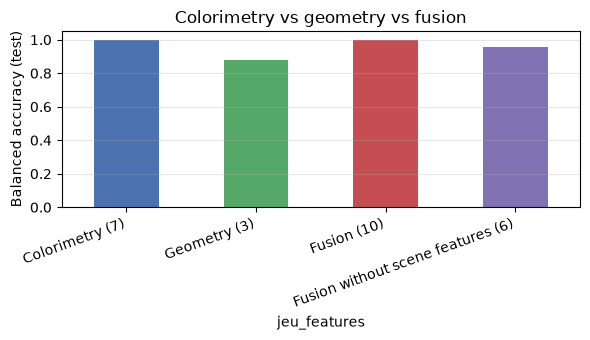


--- Fusion (10 features) ---
              precision    recall  f1-score   support

         pre       1.00      1.00      1.00        96
         per       1.00      1.00      1.00        98
        post       1.00      1.00      1.00        98

    accuracy                           1.00       292
   macro avg       1.00      1.00      1.00       292
weighted avg       1.00      1.00      1.00       292



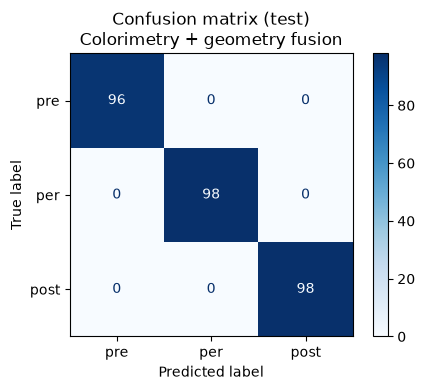

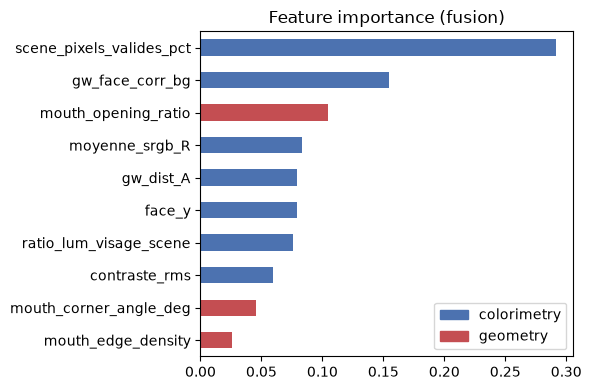

Importance share by method:
 colorimetry    0.824
geometry       0.176


In [40]:
# Final evaluation on the TEST set (only once)
lignes, preds = [], {}
for nom_jeu, feats in JEUX_FEATURES.items():
    pred = final_models[nom_jeu].predict(d_test[feats])
    preds[nom_jeu] = pred
    lignes.append({"jeu_features": nom_jeu, "n_features": len(feats),
                   "accuracy": accuracy_score(y_test, pred),
                   "balanced_accuracy": balanced_accuracy_score(y_test, pred)})
resume = pd.DataFrame(lignes).set_index("jeu_features").round(3)
print(resume)

fig, ax = plt.subplots(figsize=(6, 3.5))
resume["balanced_accuracy"].plot.bar(ax=ax, color=["#4C72B0", "#55A868", "#C44E52", "#8172B3"])
ax.set_ylim(0, 1.05); ax.set_ylabel("Balanced accuracy (test)"); ax.grid(axis="y", alpha=.3)
ax.set_title("Colorimetry vs geometry vs fusion"); plt.xticks(rotation=20, ha="right")
plt.tight_layout(); plt.savefig("figures/comparaison_fusion.png", dpi=150, bbox_inches="tight"); plt.show()

# Detailed report + confusion matrix for the fusion model
print("\n--- Fusion (10 features) ---")
print(classification_report(y_test, preds["Fusion (10)"], labels=GROUPES, zero_division=0))
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, preds["Fusion (10)"], labels=GROUPES, cmap="Blues", ax=ax)
ax.set_title("Confusion matrix (test)\nColorimetry + geometry fusion")
plt.tight_layout(); plt.savefig("figures/confusion_fusion.png", dpi=150, bbox_inches="tight"); plt.show()

# Feature importance in the fused model
rf = final_models["Fusion (10)"]
imp = pd.Series(rf.feature_importances_, index=TOP_FUSION).sort_values()
couleurs = ["#4C72B0" if SOURCE[f] == "colorimetry" else "#C44E52" for f in imp.index]
fig, ax = plt.subplots(figsize=(6, 4))
imp.plot.barh(ax=ax, color=couleurs, title="Feature importance (fusion)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#4C72B0"), plt.Rectangle((0, 0), 1, 1, color="#C44E52")],
          labels=["colorimetry", "geometry"], loc="lower right")
plt.tight_layout(); plt.savefig("figures/importance_fusion.png", dpi=150, bbox_inches="tight"); plt.show()

part = imp.groupby(imp.index.map(SOURCE)).sum().round(3)
print("Importance share by method:\n", part.to_string())

### Selected Model: Scene-Free Fusion (6)

Selected because it uses only facial features (no background or lighting features), making it more likely to generalize to new videos and individuals. It performs significantly better than facial geometry alone.

Selected model: Fusion without scene features (6)
Features (6): ['moyenne_srgb_R', 'contraste_rms', 'face_y', 'mouth_opening_ratio', 'mouth_corner_angle_deg', 'mouth_edge_density']
Test accuracy          : 0.959
Test balanced accuracy : 0.959

              precision    recall  f1-score   support

         pre       0.97      0.97      0.97        96
         per       0.95      0.98      0.96        98
        post       0.96      0.93      0.94        98

    accuracy                           0.96       292
   macro avg       0.96      0.96      0.96       292
weighted avg       0.96      0.96      0.96       292



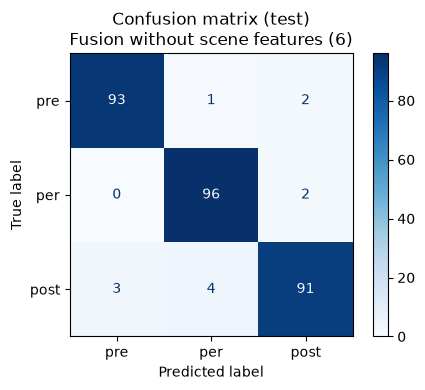

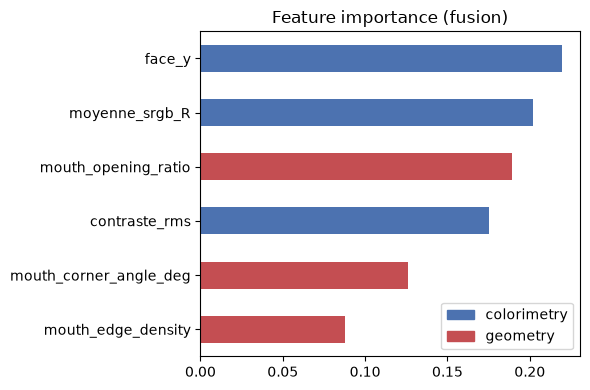

Importance share by method:
 colorimetry    0.596
geometry       0.404
Model saved: models/FUSION_WITHOUT_SCENE_rf.joblib


In [45]:
import joblib

CHOSEN_MODEL_NAME = f"Fusion without scene features ({len(TOP_FUSION_WITHOUT_SCENE)})"
selected_model = final_models[CHOSEN_MODEL_NAME]
selected_features = JEUX_FEATURES[CHOSEN_MODEL_NAME]
chosen_pred = preds[CHOSEN_MODEL_NAME]

print(f"Selected model: {CHOSEN_MODEL_NAME}")
print(f"Features ({len(selected_features)}): {selected_features}")
print(f"Test accuracy          : {accuracy_score(y_test, chosen_pred):.3f}")
print(f"Test balanced accuracy : {balanced_accuracy_score(y_test, chosen_pred):.3f}\n")
print(classification_report(y_test, chosen_pred, labels=GROUPES, zero_division=0))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, chosen_pred, labels=GROUPES, cmap="Blues", ax=ax)
ax.set_title(f"Confusion matrix (test)\n{CHOSEN_MODEL_NAME}")
plt.tight_layout(); plt.savefig("figures/confusion_selected_model.png", dpi=150, bbox_inches="tight"); plt.show()

# Save for later use (temporal analysis, new images)
Path("models").mkdir(exist_ok=True)
joblib.dump({"modele": selected_model, "features": selected_features,
             "classes": list(selected_model.classes_), "roi_ratio": ROI_RATIO},
            "models/FUSION_WITHOUT_SCENE_rf.joblib")


# Feature importance in the fused model
rf = final_models[CHOSEN_MODEL_NAME]
imp = pd.Series(rf.feature_importances_, index=selected_features).sort_values()
couleurs = ["#4C72B0" if SOURCE[f] == "colorimetry" else "#C44E52" for f in imp.index]
fig, ax = plt.subplots(figsize=(6, 4))
imp.plot.barh(ax=ax, color=couleurs, title="Feature importance (fusion)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#4C72B0"), plt.Rectangle((0, 0), 1, 1, color="#C44E52")],
          labels=["colorimetry", "geometry"], loc="lower right")
plt.tight_layout(); plt.savefig("figures/importance_fusion.png", dpi=150, bbox_inches="tight"); plt.show()
part = imp.groupby(imp.index.map(SOURCE)).sum().round(3)
print("Importance share by method:\n", part.to_string())


print("Model saved: models/FUSION_WITHOUT_SCENE_rf.joblib")

In [47]:
def test_image(chemin, jeu=None):
    """Classifies an image (pre / per / post) using the selected model (fusion without scene features) and displays the probabilities."""
    jeu = jeu or CHOSEN_MODEL_NAME
    feats = extract_features(chemin)
    if feats is None:
        print("Image unusable (no face or landmarks not found).")
        return None
    cols = JEUX_FEATURES[jeu]
    X = pd.DataFrame([feats])[cols]
    modele = final_models[jeu]
    pred = modele.predict(X)[0]
    proba = pd.Series(modele.predict_proba(X)[0], index=modele.classes_).reindex(GROUPES)

    img = cv2.cvtColor(cv2.imread(str(chemin)), cv2.COLOR_BGR2RGB)
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    axes[0].imshow(img); axes[0].axis("off")
    proba.plot.bar(ax=axes[1], color=["#4C72B0", "#55A868", "#C44E52"]); axes[1].set_ylim(0, 1)
    axes[1].tick_params(axis="x", rotation=0); axes[1].set_title("Class probabilities")
    plt.suptitle(f"{Path(chemin).name}  ->  {pred.upper()}")
    plt.tight_layout(); plt.show()
    return pred

# Example: test_image(d_test["chemin"].iloc[0])